# Permutation matrices: rearrange rows, columns, and pixels

A permutation matrix reorders entries without changing their values. If `P` is a permutation matrix, then left multiplication, `P*A`, rearranges the rows of `A`; right multiplication, `A*Q`, rearranges its columns. Because every row and column of a permutation matrix contains exactly one `1`, it is orthogonal: `P'P = I`.

Images are arrays too, so we can rearrange their rows, columns, or square blocks of pixels. We will compare these operations and see how a two-dimensional pixel permutation can also be represented as a matrix acting on the flattened image.

## 1. Permute the rows and columns of a matrix

In Julia, an index vector `p` specifies the new order: `A[p, :]` selects rows in that order. The corresponding permutation matrix is the identity with its rows reordered, so `P*A` gives the same result.

In [1]:
using LinearAlgebra
using Images
using ImageIO

A = reshape(1:12, 3, 4)
row_order = [3, 1, 2]
P = Matrix{Int}(I, 3, 3)[row_order, :]
(A, A[row_order, :], P * A, P' * P)

([1 4 7 10; 2 5 8 11; 3 6 9 12], [3 6 9 12; 1 4 7 10; 2 5 8 11], [3 6 9 12; 1 4 7 10; 2 5 8 11], [1 0 0; 0 1 0; 0 0 1])

The second and third matrices should match, and `P'P` is the identity. To permute columns instead, multiply on the right by a permutation matrix. Because right multiplication selects columns in the order specified by the permutation matrix's columns, the corresponding matrix is `Q = I[:, column_order]`.

In [2]:
column_order = [4, 2, 1, 3]
Q = Matrix{Int}(I, 4, 4)[:, column_order]
(A[:, column_order], A * Q, norm(A[:, column_order] - A * Q))

([10 4 1 7; 11 5 2 8; 12 6 3 9], [10 4 1 7; 11 5 2 8; 12 6 3 9], 0.0)

## 2. Show the original color image

Before rearranging pixels, display the image in its original form. The examples below keep the same pixel values and only change where they appear.

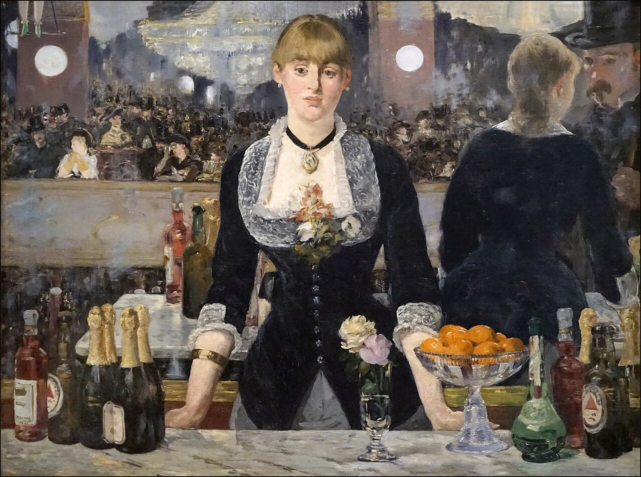

In [3]:
image_path = joinpath(@__DIR__, "..", "images", "bar-at-folies-bergere.jpg")
original = load(image_path)
original

## 3. Permute image rows and columns

A row permutation moves whole horizontal strips; a column permutation moves vertical strips. We use a reduced copy to keep the visual comparison responsive. Cyclic shifts are especially simple permutations: each row or column wraps around at the edge.

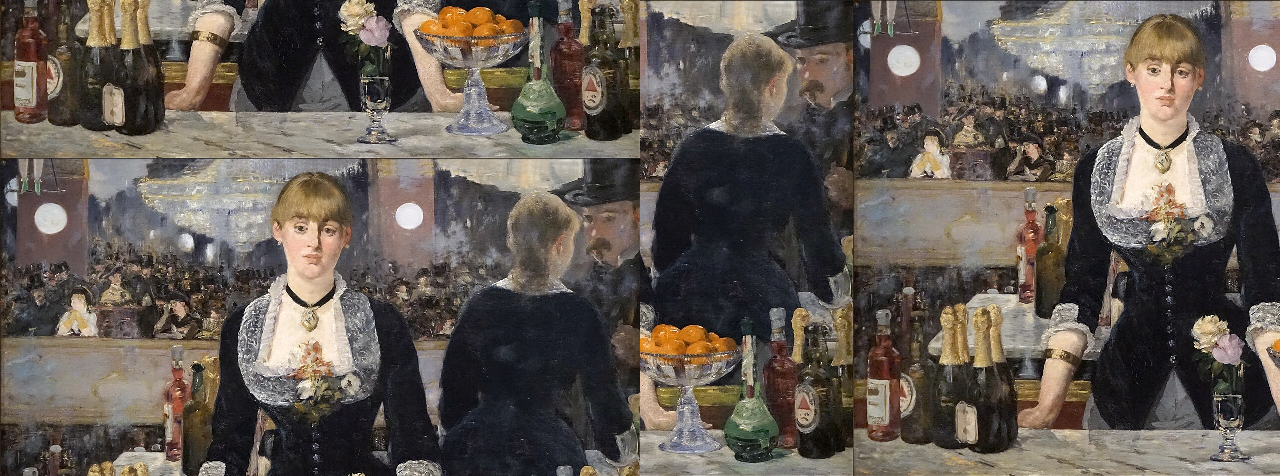

In [4]:
image = original[1:2:end, 1:2:end]
row_shift = size(image, 1) ÷ 3
column_shift = size(image, 2) ÷ 3
row_permuted = circshift(image, (row_shift, 0))
column_permuted = circshift(image, (0, column_shift))
hcat(row_permuted, column_permuted)

Each result is still the same collection of pixels. The wraparound at the image boundary is a consequence of the cyclic permutation; it is not part of an ordinary translation with empty space.

## 4. Rearrange square pixel blocks

Flatten each `block_size × block_size` block into a vector and reorder the blocks. This changes the image dramatically while preserving every pixel and its color. We trim the image dimensions to a multiple of the block size so each block has the same shape.

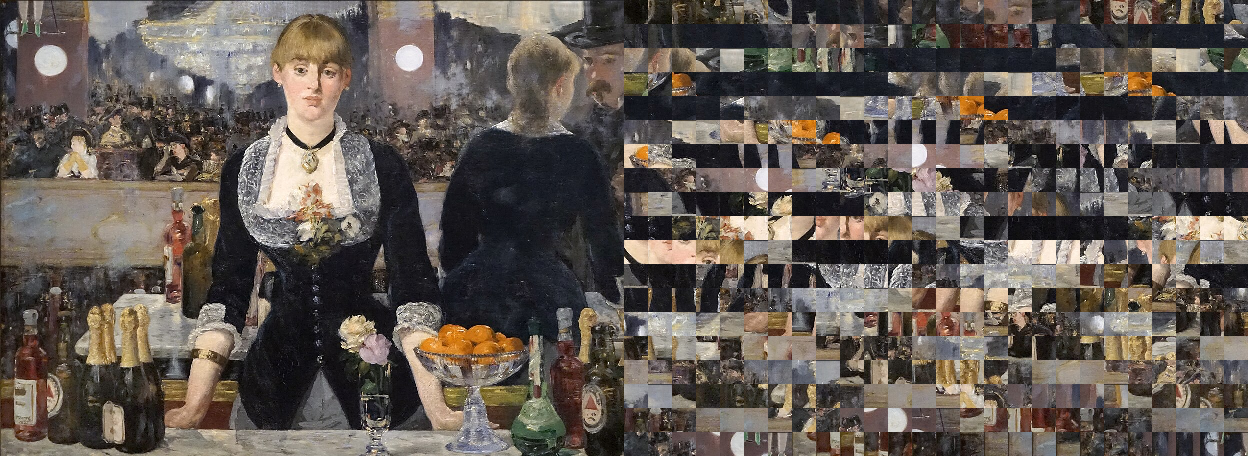

In [5]:
block_size = 24
height = (size(image, 1) ÷ block_size) * block_size
width = (size(image, 2) ÷ block_size) * block_size
block_image = image[1:height, 1:width]
block_rows = height ÷ block_size
block_cols = width ÷ block_size
blocks = [block_image[(row-1)*block_size+1:row*block_size, (col-1)*block_size+1:col*block_size]
          for row in 1:block_rows, col in 1:block_cols]
block_order = reverse(1:length(blocks))
permuted_blocks = similar(blocks)
permuted_blocks[:] = blocks[block_order]

block_permuted_image = similar(block_image)
for index in eachindex(permuted_blocks)
    row = fld(index - 1, block_cols) + 1
    col = mod(index - 1, block_cols) + 1
    block_permuted_image[(row-1)*block_size+1:row*block_size, (col-1)*block_size+1:col*block_size] = permuted_blocks[index]
end
hcat(block_image, block_permuted_image)

A block permutation is also a permutation matrix: it rearranges the coordinates of the flattened image. For an image with `N` pixels, that matrix would be `N × N` and mostly zeros. We can apply the same permutation by rearranging blocks directly without constructing this enormous matrix.

## 5. Flattened images and permutation matrices

For a tiny grayscale crop, we can explicitly construct a permutation matrix that reverses the flattened pixel order. Each column of `P_pixels` identifies the destination location of one input pixel. Applying it to the flattened pixels and reshaping the result performs exactly that rearrangement.

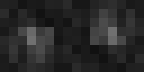

In [6]:
small_gray = Float64.(Gray.(block_image[1:8, 1:8]))
small_height, small_width = size(small_gray)
pixel_order = reverse(collect(eachindex(small_gray)))
P_pixels = Matrix{Float64}(I, length(pixel_order), length(pixel_order))[:, pixel_order]
permuted_pixels = reshape(P_pixels' * vec(small_gray), size(small_gray))
hcat(Gray.(small_gray), Gray.(permuted_pixels))

The flattened order is reversed, but the pixel values themselves are unchanged. Try changing `pixel_order` to see how another permutation moves pixels. Constructing a dense permutation matrix only makes sense for a tiny image; for real images, indexing and reshaping perform the same rearrangement much more efficiently.

## Your turn

1. Choose a different `row_order`. Confirm that `P * A` matches `A[row_order, :]`.
2. Apply the same row permutation twice. Which permutation returns the original matrix?
3. Change `block_order` to a random permutation. What visual structure survives when the blocks are small? What survives when they are large?
4. Change `pixel_order` to reverse all pixels or to swap two pixels, then confirm that sorting the pixel values gives the same collection before and after.

Permutation matrices are orthogonal and preserve vector length, dot products, and matrix rank. They rearrange data, but do not alter its values.